In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyArrowPatch
import jax
import jax.numpy as jnp
from jax import jacfwd, jit

In [2]:
m = 1
g = 9.81
dt = 0.05

# Fixed point (hover)
x_fixed = np.array([[0.0], [0.0], [0.0], [0.0], [0.0], [0.0]])
u_fixed = np.array([[m * g], [0.0]]) 

def dynamics(x,u):
    J = 0.05 # Inertia

    # Constants
    k_x = 0.3 # Drag coefficient along body x-axis
    k_y = 0.3 # Drag coefficient along body y-axis
    k_theta = 0.02 # Drag coefficient for θ_dot

    # Extract info from x,u vectors
    theta = x[2, 0]
    x_dot = x[3, 0]
    y_dot = x[4, 0]
    theta_dot = x[5, 0]
    T = u[0, 0]
    tau = u[1, 0]

    # Calculate local velocities (v_x, v_y)
    v_x = x_dot * jnp.cos(theta) + y_dot * jnp.sin(theta)
    v_y = -x_dot * jnp.sin(theta) + y_dot * jnp.cos(theta) 

    # Calculate drag forces
    f_x = -k_x * v_x * jnp.abs(v_x)
    f_y = -k_y * v_y * jnp.abs(v_y)
    f_theta = -k_theta * theta_dot
    
    # Global x-acceleration
    x_ddot = (1/m) * (-jnp.sin(theta) * (T + f_y) + jnp.cos(theta) * f_x)

    # Global y-acceleration 
    y_ddot = (1/m) * (jnp.cos(theta) * (T + f_y) + jnp.sin(theta) * f_x) - g
    
    # Angular acceleration
    theta_ddot = (tau - f_theta) / J

    f = jnp.block([[x_dot], [y_dot], [theta_dot], [x_ddot], [y_ddot], [theta_ddot]])
    return f


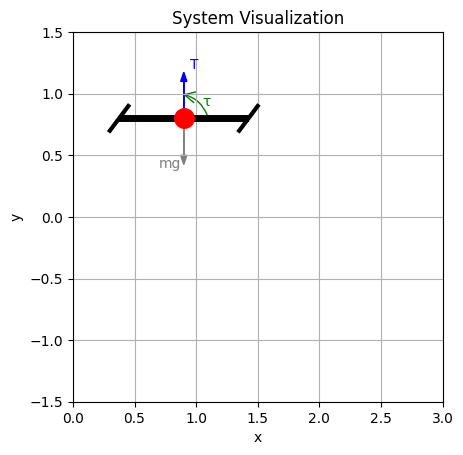

In [3]:
# position for quadrotor visualization
x = jnp.array([[0.9], [0.8], [0.5], [0.0], [0.0], [0.0]]) 
# u = np.array([[0.0], [0.0]])               

# =====================================================
# 1. VISUALIZATION
# =====================================================
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.set_xlim(0, 3.0)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('System Visualization')

# Body of the quadrotor
ax.plot([0.4, 1.4], [x[1, 0], x[1, 0]], 'k-', lw=5)
ax.plot([0.3, 0.45], [0.7, 0.9], 'k-', lw=3)
ax.plot([1.35, 1.5], [0.7, 0.9], 'k-', lw=3)

# Mass
ax.plot(x[0, 0], x[1, 0], 'ro', markersize=14)

# Gravity arrow
ax.arrow(x[0, 0], x[1, 0], 0, -0.3, head_width=0.05, color='gray')
ax.text(x[0, 0] - 0.2, x[1, 0] - 0.4, 'mg', fontsize=10, color='gray')

# T force arrow
ax.arrow(x[0, 0], x[1, 0], 0, 0.3, head_width=0.05, color='blue')
ax.text(x[0, 0] + 0.05, x[1, 0] + 0.4, 'T', fontsize=10, color='blue')

# τ force arrow
tau = FancyArrowPatch(
    posA=(1.1, x[1, 0]),     
    posB=(0.87, 1.0),        
    connectionstyle="arc3,rad=0.3",  
    arrowstyle="->",     
    mutation_scale=20,   
    color="green"
)
ax.add_patch(tau)
ax.text(1.05 , 0.9, 'τ', fontsize=10, color='green')

plt.grid(True)
plt.show()

In [4]:
# =====================================================
# 2. DISCRETIZATION
# =====================================================
def rk4(x, u, dt):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1 * (dt/2), u)
    f3 = dynamics(x + f2 * (dt/2), u)
    f4 = dynamics(x + f3 * dt, u)
    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4)

    return x_n

In [5]:
# initial state and control
x = jnp.array([[0.9], [0.8], [0.0], [0.0], [0.0], [0.0]]) 
u = u_fixed

# =====================================================
# 3. SIMULATION
# =====================================================
T = 10 # total time of simulation                 
dt = 0.05 # time step              
K = int(T / dt) + 1
print("K = ", K)

# Simulation loop
xs = [jnp.copy(x)]
for k in range(K):
    x = rk4(x, u, dt)
    xs.append(jnp.copy(x))
xs = jnp.array(xs)

K =  201


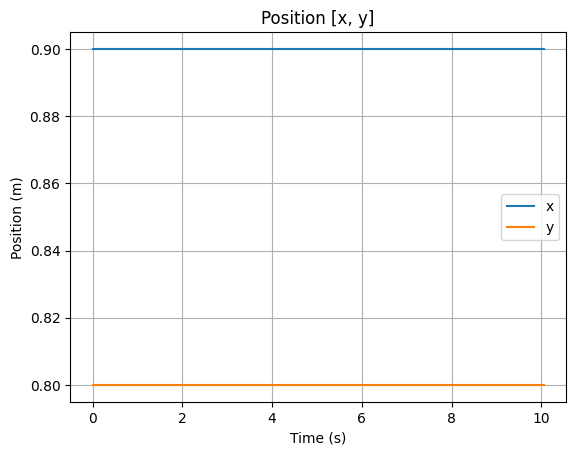

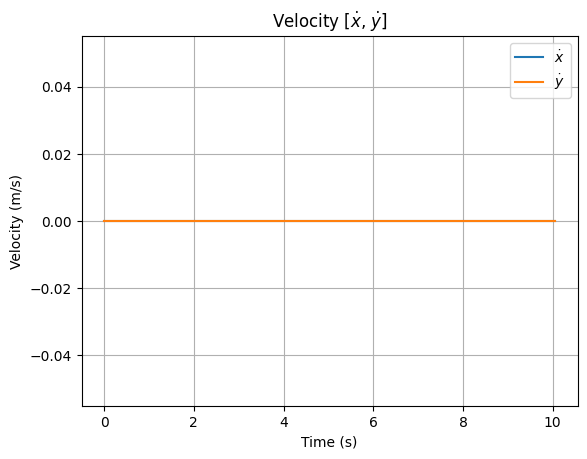

In [6]:
fig1, ax1 = plt.subplots()
ax1.plot([k*dt for k in range(K+1)], xs[:,0], label = 'x')
ax1.plot([k*dt for k in range(K+1)], xs[:,1], label = 'y')
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Position [x, y]")
plt.legend()
plt.grid(True)

fig2, ax2 = plt.subplots()
ax2.plot([k*dt for k in range(K+1)], xs[:,3], label = '$\dot{x}$')
ax2.plot([k*dt for k in range(K+1)], xs[:,4], label = '$\dot{y}$')
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Velocity [$\dot{x}$, $\dot{y}$]")
plt.legend()
plt.grid(True)

plt.show()